# 02 Error analysis

Every model is already scored in `results/<run>/metrics.json`. That tells us *how many*
mistakes each model makes. This notebook asks *which* essays they get wrong and why.

All of it uses the **topic split**, where val and test contain essay prompts no model has
seen during training. That is the hard setting and the one the report compares on.

The eight questions:

1. Which test topics do the errors come from?
2. Do longer essays get more errors, and does DistilBERT's 512-token limit hurt?
3. Which language models write the AI essays that slip through?
4. How large is the uncertainty on each number (bootstrap confidence intervals)?
5. Where do logistic regression and DistilBERT disagree, and what do the errors look like?
6. Did the models learn topic words rather than style ("car")?
7. DistilBERT against ModernBERT, head to head.

Prerequisites: `uv run python -m essaydetect.data` has been run, and the four topic-split
runs exist in `results/` (`lr_topic`, `svm_topic`, `distilbert_topic`, `modernbert_topic`).


## Setup

`predictions.csv` deliberately contains no essay text, to keep the repository small and
to avoid redistributing the dataset. So we read the test split (which has the text) and
**join on `id`** to attach each model's prediction to the essay it belongs to.

After the join every row is one essay as judged by one model, and `outcome` says what
happened:

- **false positive** - a student essay flagged as AI. The error a teacher cares about most.
- **miss** - an AI essay that was predicted to be student-written.
- **correct** - everything else.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from essaydetect.data import LABEL_COL, SOURCE_COL, TEXT_COL, TOPIC_COL

# VS Code runs notebooks from the notebooks/ folder, so step up to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Write one figure to results/figures/<name>.png for the report."""
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path.relative_to(ROOT)}")


# The four topic-split runs, with short names for the tables and plots.
MODELS = {
    "lr_topic": "LR",
    "svm_topic": "SVM",
    "distilbert_topic": "DistilBERT",
    "modernbert_topic": "ModernBERT",
}
ORDER = list(MODELS.values())  # keeps every table in the same column order

# Shorter topic names, used only in the plots so the labels fit.
SHORT_TOPIC = {
    "Driverless cars": "Driverless\ncars",
    "Exploring Venus": "Exploring\nVenus",
    "Grades for extracurricular activities": "Grades for\nextracurriculars",
}

test = pd.read_csv(ROOT / "data/splits/topic/test.csv")
test["n_words"] = test[TEXT_COL].str.split().str.len()

frames = []
for run, short in MODELS.items():
    predictions = pd.read_csv(
        ROOT / f"results/{run}/predictions.csv", usecols=["id", "pred", "score"]
    )
    merged = test.merge(predictions, on="id", validate="one_to_one")
    merged["model"] = short
    frames.append(merged)
errors = pd.concat(frames, ignore_index=True)

errors["outcome"] = np.select(
    [
        (errors[LABEL_COL] == 0) & (errors["pred"] == 1),  # student essay flagged as AI
        (errors[LABEL_COL] == 1) & (errors["pred"] == 0),  # AI essay that slipped through
    ],
    ["false positive", "miss"],
    default="correct",
)
errors["is_error"] = errors["outcome"] != "correct"

print(f"{len(test):,} test essays x {len(MODELS)} models = {len(errors):,} rows")
errors.pivot_table(index="model", columns="outcome", values="id", aggfunc="count").loc[ORDER]


6,542 test essays x 4 models = 26,168 rows


outcome,correct,false positive,miss
model,,,
LR,6214,297,31
SVM,6239,275,28
DistilBERT,6271,264,7
ModernBERT,6489,48,5


### Token counts

Two of the questions need to know how many **tokens** each essay has, not just words. A
token is a word or a piece of a word, so essays have more tokens than words. DistilBERT
cannot read more than 512 of them: everything after that is cut off, so the model judges
an unfinished essay.

This counts the tokens without truncating, so we can see which essays were affected. The
warning about sequences longer than 512 is expected - we only count, we never run the model.


In [2]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
encoded = tokenizer(test[TEXT_COL].tolist(), truncation=False, verbose=False)["input_ids"]
test["n_tokens"] = [len(ids) for ids in encoded]
test["over_512"] = test["n_tokens"] > 512

errors = errors.merge(test[["id", "n_tokens", "over_512"]], on="id")

print(f"median {test['n_tokens'].median():.0f} tokens")
print(f"{test['over_512'].mean():.1%} of the test essays are cut off at 512 tokens")


c:\ai-essay-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


median 386 tokens
22.7% of the test essays are cut off at 512 tokens


## 1. Errors per test topic and model

The topic split has three test topics. Counts alone are misleading, because the topics
differ in size and in class balance, so each error kind is shown as both a count and a
rate:

- **false positive rate** = flagged student essays / all student essays *in that topic*
- **miss rate** = missed AI essays / all AI essays *in that topic*

If the errors were spread evenly, every topic would show a similar rate. They are not.


In [3]:
def by_topic(kind, true_label):
    """Counts and rates of one error kind, per topic and model."""
    subset = errors[errors[LABEL_COL] == true_label].assign(hit=lambda d: d["outcome"] == kind)
    counts = subset.pivot_table(index=TOPIC_COL, columns="model", values="hit", aggfunc="sum")
    rates = subset.pivot_table(index=TOPIC_COL, columns="model", values="hit", aggfunc="mean")
    return counts[ORDER].astype(int), rates[ORDER]


fp_counts, fp_rates = by_topic("false positive", true_label=0)
miss_counts, miss_rates = by_topic("miss", true_label=1)

n_per_topic = test.groupby(TOPIC_COL)[LABEL_COL].agg(n_essays="size", n_ai="sum")
n_per_topic["n_student"] = n_per_topic["n_essays"] - n_per_topic["n_ai"]
display(n_per_topic)

print("\nFalse positives per topic (student essays flagged as AI)")
display(fp_counts)
display(fp_rates.round(3))

print("\nMisses per topic (AI essays predicted to be student-written)")
display(miss_counts)
display(miss_rates.round(3))


,n_essays,n_ai,n_student
prompt_name,,,
Driverless cars,2250,364,1886
Exploring Venus,2176,314,1862
Grades for extracurricular activities,2116,490,1626



False positives per topic (student essays flagged as AI)


model,LR,SVM,DistilBERT,ModernBERT
prompt_name,,,,
Driverless cars,2,0,13,0
Exploring Venus,293,273,196,17
Grades for extracurricular activities,2,2,55,31


model,LR,SVM,DistilBERT,ModernBERT
prompt_name,,,,
Driverless cars,0.001,0.000,0.007,0.000
Exploring Venus,0.157,0.147,0.105,0.009
Grades for extracurricular activities,0.001,0.001,0.034,0.019



Misses per topic (AI essays predicted to be student-written)


model,LR,SVM,DistilBERT,ModernBERT
prompt_name,,,,
Driverless cars,16,15,5,4
Exploring Venus,0,0,0,0
Grades for extracurricular activities,15,13,2,1


model,LR,SVM,DistilBERT,ModernBERT
prompt_name,,,,
Driverless cars,0.044,0.041,0.014,0.011
Exploring Venus,0.000,0.000,0.000,0.000
Grades for extracurricular activities,0.031,0.027,0.004,0.002


saved results\figures\errors_by_topic.png


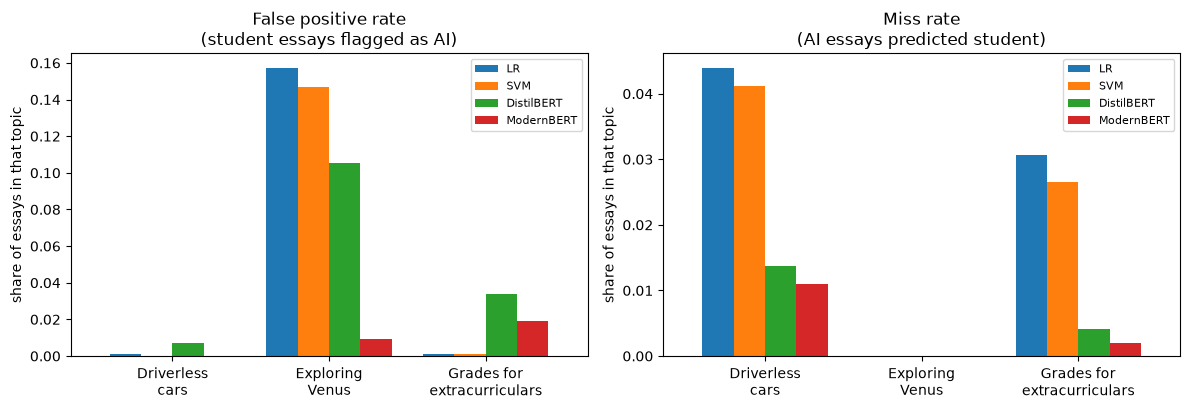

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
panels = [
    (fp_rates, "False positive rate\n(student essays flagged as AI)"),
    (miss_rates, "Miss rate\n(AI essays predicted student)"),
]
for ax, (table, title) in zip(axes, panels):
    table.rename(index=SHORT_TOPIC).plot.bar(ax=ax, rot=0, width=0.8)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("share of essays in that topic")
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "errors_by_topic")
plt.show()


## 2. Error rate by essay length

Two ways of asking whether length matters:

- **Word-count bins.** Simply: are long essays harder? The number of essays per bin is
  shown too, because a rate computed from very few essays jumps around.
- **Above or below 512 DistilBERT tokens.** This is the interesting one. DistilBERT loses
  the ending of every essay above the line; ModernBERT reads up to 1024 tokens and keeps
  almost all of them. If truncation hurts, DistilBERT's error rate should rise above the
  line while ModernBERT's stays flat.

The comparison is between the two transformers only, since the classical models have no
length limit at all.


In [5]:
pair = ["DistilBERT", "ModernBERT"]
two = errors[errors["model"].isin(pair)].copy()
two["length_bin"] = pd.cut(
    two["n_words"],
    bins=[0, 200, 300, 400, 500, np.inf],
    labels=["<200", "200-299", "300-399", "400-499", "500+"],
)

by_length = two.pivot_table(
    index="length_bin", columns="model", values="is_error", aggfunc="mean", observed=True
)[pair]
by_length.insert(0, "n_essays", two[two["model"] == "DistilBERT"].groupby("length_bin", observed=True).size())
print("Error rate by essay length in words")
display(by_length.round(4))

by_truncation = two.pivot_table(index="over_512", columns="model", values="is_error", aggfunc="mean")[pair]
by_truncation.insert(0, "n_essays", two[two["model"] == "DistilBERT"].groupby("over_512").size())
by_truncation.index = by_truncation.index.map(
    {False: "512 tokens or fewer", True: "longer than 512 (cut off for DistilBERT)"}
)
print("\nError rate below and above DistilBERT's token limit")
display(by_truncation.round(4))


Error rate by essay length in words


model,n_essays,DistilBERT,ModernBERT
length_bin,,,
<200,673,0.0654,0.0119
200-299,2032,0.0418,0.0094
300-399,1946,0.0411,0.0057
400-499,1052,0.0266,0.0095
500+,839,0.0405,0.0060



Error rate below and above DistilBERT's token limit


model,n_essays,DistilBERT,ModernBERT
over_512,,,
512 tokens or fewer,5059,0.0429,0.0081
longer than 512 (cut off for DistilBERT),1483,0.0364,0.0081


saved results\figures\errors_by_length.png


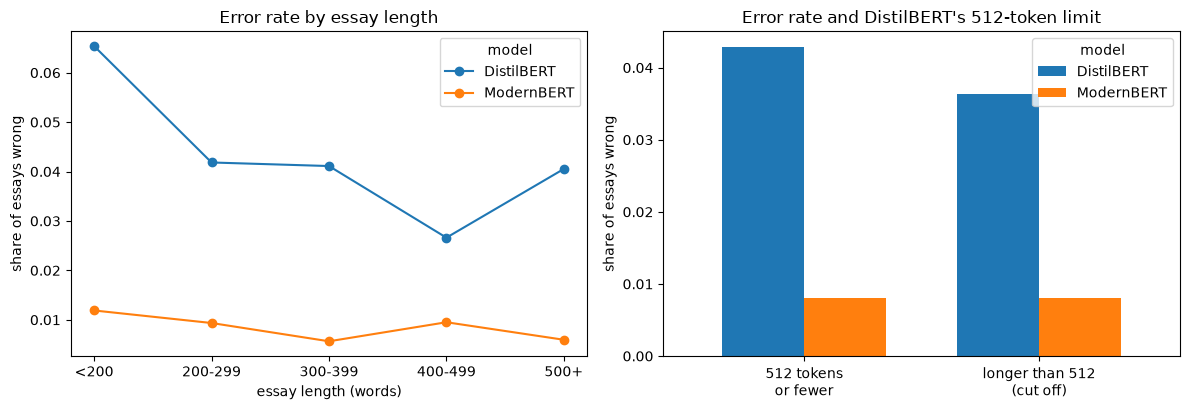

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

by_length[pair].plot(ax=axes[0], marker="o")
axes[0].set_title("Error rate by essay length")
axes[0].set_xlabel("essay length (words)")
axes[0].set_ylabel("share of essays wrong")
axes[0].set_xticks(range(len(by_length)))
axes[0].set_xticklabels(by_length.index, rotation=0)

by_truncation[pair].plot.bar(ax=axes[1], rot=0, width=0.7)
axes[1].set_title("Error rate and DistilBERT's 512-token limit")
axes[1].set_xlabel("")
axes[1].set_ylabel("share of essays wrong")
axes[1].set_xticklabels(["512 tokens\nor fewer", "longer than 512\n(cut off)"])

fig.tight_layout()
save_fig(fig, "errors_by_length")
plt.show()


## 3. Misses by source model

The `source` column says who wrote each essay: a student corpus for label 0, and the name
of a language model for label 1. So for the AI essays we can ask which generators are
hardest to catch. A high miss rate for one source means that model's writing looks most
like a student's - useful to say in the report, and a limitation: the result depends on
which generators happen to be in DAIGT v2.


In [7]:
ai_only = errors[errors[LABEL_COL] == 1].assign(miss=lambda d: d["outcome"] == "miss")

miss_by_source = ai_only.pivot_table(
    index=SOURCE_COL, columns="model", values="miss", aggfunc="mean"
)[ORDER]
miss_by_source.insert(
    0, "n_essays", ai_only[ai_only["model"] == "LR"].groupby(SOURCE_COL).size()
)
miss_by_source = miss_by_source.sort_values("DistilBERT", ascending=False)
print("Miss rate per source model (share of that model's essays that slipped through)")
display(miss_by_source.round(3))


Miss rate per source model (share of that model's essays that slipped through)


model,n_essays,LR,SVM,DistilBERT,ModernBERT
source,,,,,
cohere-command,100,0.070,0.070,0.040,0.040
mistral7binstruct_v2,45,0.089,0.089,0.022,0.022
llama_70b_v1,174,0.115,0.098,0.011,0.000
chat_gpt_moth,38,0.000,0.000,0.000,0.000
darragh_claude_v6,222,0.000,0.000,0.000,0.000
darragh_claude_v7,197,0.000,0.000,0.000,0.000
llama2_chat,102,0.000,0.000,0.000,0.000
falcon_180b_v1,135,0.000,0.000,0.000,0.000
mistral7binstruct_v1,55,0.000,0.000,0.000,0.000


saved results\figures\misses_by_source.png


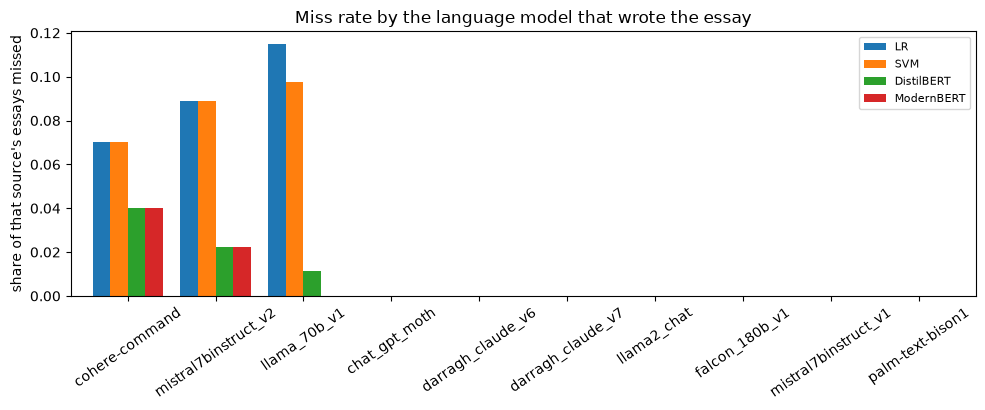

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
miss_by_source[ORDER].plot.bar(ax=ax, rot=35, width=0.8)
ax.set_title("Miss rate by the language model that wrote the essay")
ax.set_xlabel("")
ax.set_ylabel("share of that source's essays missed")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "misses_by_source")
plt.show()


## 4. Bootstrap confidence intervals

Every number in the results table comes from one test set. If we had drawn a different
sample of essays, we would have got slightly different numbers. A **bootstrap** estimates
how much: draw a new test set of the same size from the one we have, *with replacement*
(so some essays appear twice and others not at all), recompute the metric, and repeat
1,000 times. The middle 95 % of those 1,000 values is the confidence interval.

Read it like this: if two models' intervals overlap a lot, the test set is not big enough
to say which is better. This is the honest way to report a one-run comparison, and it is
cheap - no retraining, just resampling the predictions we already have.


In [9]:
from sklearn.metrics import roc_auc_score

METRICS = ["false positive rate", "AI recall", "ROC-AUC"]


def three_metrics(label, pred, score):
    """False positive rate, AI recall and ROC-AUC for one (re)sample."""
    fp_rate = ((label == 0) & (pred == 1)).sum() / (label == 0).sum()
    recall = ((label == 1) & (pred == 1)).sum() / (label == 1).sum()
    return fp_rate, recall, roc_auc_score(label, score)


def bootstrap_ci(frame, n_resamples=1000, seed=42):
    """Point estimate and 95 % interval for the three metrics."""
    rng = np.random.default_rng(seed)
    label = frame[LABEL_COL].to_numpy()
    pred = frame["pred"].to_numpy()
    score = frame["score"].to_numpy()

    draws = []
    for _ in range(n_resamples):
        # Pick len(label) row numbers at random, with repeats allowed.
        pick = rng.integers(0, len(label), len(label))
        draws.append(three_metrics(label[pick], pred[pick], score[pick]))

    low, high = np.percentile(draws, [2.5, 97.5], axis=0)
    return three_metrics(label, pred, score), low, high


rows = []
for short in ORDER:
    point, low, high = bootstrap_ci(errors[errors["model"] == short])
    for metric, value, lo, hi in zip(METRICS, point, low, high):
        rows.append({"model": short, "metric": metric, "value": value, "ci_low": lo, "ci_high": hi})
ci_table = pd.DataFrame(rows)

for metric in METRICS:
    print(f"\n{metric}")
    display(ci_table[ci_table["metric"] == metric].set_index("model")[["value", "ci_low", "ci_high"]].round(4))



false positive rate


,value,ci_low,ci_high
model,,,
LR,0.0553,0.0496,0.0614
SVM,0.0512,0.0457,0.0569
DistilBERT,0.0491,0.0433,0.0546
ModernBERT,0.0089,0.0063,0.0115



AI recall


,value,ci_low,ci_high
model,,,
LR,0.9735,0.9641,0.9830
SVM,0.9760,0.9671,0.9849
DistilBERT,0.9940,0.9891,0.9982
ModernBERT,0.9957,0.9917,0.9991



ROC-AUC


,value,ci_low,ci_high
model,,,
LR,0.9924,0.9892,0.9951
SVM,0.9941,0.9914,0.9963
DistilBERT,0.9989,0.9983,0.9994
ModernBERT,0.9992,0.9987,0.9997


saved results\figures\bootstrap_ci.png


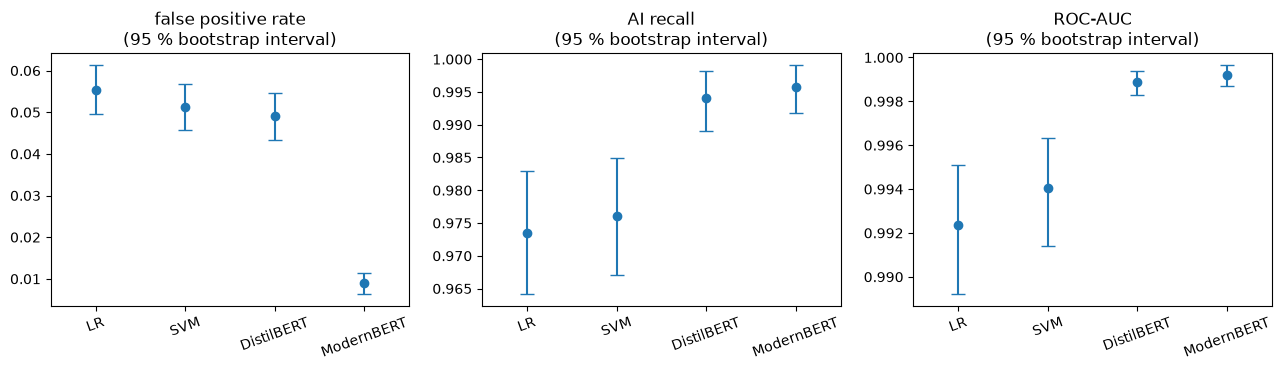

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric in zip(axes, METRICS):
    sub = ci_table[ci_table["metric"] == metric].set_index("model").loc[ORDER]
    ax.errorbar(
        range(len(sub)),
        sub["value"],
        yerr=[sub["value"] - sub["ci_low"], sub["ci_high"] - sub["value"]],
        fmt="o",
        capsize=5,
    )
    ax.set_title(f"{metric}\n(95 % bootstrap interval)")
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub.index, rotation=20)
    ax.set_xlim(-0.5, len(sub) - 0.5)
fig.tight_layout()
save_fig(fig, "bootstrap_ci")
plt.show()


## 5. Where LR and DistilBERT disagree, and what the errors look like

First the counts: on how many essays do the simplest and the first transformer model
differ, and when they differ, which one is right? The 2x2 table answers that.

Then five false positives and five misses printed in full, because some things only show
up by reading. Look for: are the flagged student essays unusually formal or well
structured? Do the missed AI essays imitate spelling mistakes and informal phrasing?


In [11]:
wide = errors.pivot_table(index="id", columns="model", values="pred")
wide = wide.join(test.set_index("id")[[LABEL_COL, TOPIC_COL, SOURCE_COL]])

disagree = wide[wide["LR"] != wide["DistilBERT"]]
print(f"LR and DistilBERT disagree on {len(disagree):,} of {len(wide):,} test essays")

display(
    pd.crosstab(
        wide["LR"] == wide[LABEL_COL],
        wide["DistilBERT"] == wide[LABEL_COL],
        rownames=["LR correct"],
        colnames=["DistilBERT correct"],
    )
)

print("\nThe disagreements by topic and true label (0 = student, 1 = AI)")
display(disagree.groupby([TOPIC_COL, LABEL_COL]).size().to_frame("n_essays"))


LR and DistilBERT disagree on 383 of 6,542 test essays


DistilBERT correct,False,True
LR correct,,
False,108,220
True,163,6051



The disagreements by topic and true label (0 = student, 1 = AI)


n_essays
prompt_name                           label          
Driverless cars                       0            13
                                      1            11
Exploring Venus                       0           293
Grades for extracurricular activities 0            53
                                      1            13

In [12]:
def read_examples(model, kind, n=5, chars=800, seed=0):
    """Print a few of one model's errors, text included."""
    picks = errors[(errors["model"] == model) & (errors["outcome"] == kind)]
    if picks.empty:
        print(f"{model} makes no {kind} errors.")
        return
    for _, essay in picks.sample(min(n, len(picks)), random_state=seed).iterrows():
        print(
            f"--- {kind.upper()} | {essay[TOPIC_COL]} | source: {essay[SOURCE_COL]} | "
            f"{essay['n_words']} words, {essay['n_tokens']} tokens | AI score {essay['score']:.3f} ---"
        )
        print(" ".join(essay[TEXT_COL][:chars].split()), "...\n")


read_examples("DistilBERT", "false positive")
read_examples("DistilBERT", "miss")


--- FALSE POSITIVE | Exploring Venus | source: persuade_corpus | 331 words, 388 tokens | AI score 0.978 ---
"The Challenge of Exploring Venus," is an article written by someone who is arguing that Venus is a worthy exploration, despite the fact that it is highly dangerous. The author's claim was strong, and the points were valid. They included many different supported statements, and facts, and arguments that support their case very well. Throughout the article, the author gives many different statements that help support their statement that Venus is worth the risk. In paragraph 2, the author discusses all the qualities and characteristics that make Venus an ideal planet to study. Venus is most similar to Earth by means of size and density, and at times, the closest in distance. In paragraph 4, further evidence is put forth. Paragraph 4 discusses the interest scientists have in exploring Venus ...

--- FALSE POSITIVE | Exploring Venus | source: persuade_corpus | 358 words, 410 tokens 

## 6. The "car" question: style or topic words?

The worry behind the whole topic split: a model can score well by learning *topic* words
instead of *style*. One test topic is "Driverless cars", and the training topics include
car-related ones. If the car topics in training lean towards one class, the model may
learn "car" as evidence for that class and then apply it to every Driverless cars essay.

Three checks:

1. The AI share of the car-related **training** topics, against the training set overall.
2. Where car words sit among logistic regression's largest weights (saved in
   `results/lr_topic/metrics.json`).
3. Whether the errors actually cluster in Driverless cars, which is the prediction that
   follows from 1 and 2.


In [13]:
import json

train = pd.read_csv(ROOT / "data/splits/topic/train.csv", usecols=[LABEL_COL, TOPIC_COL])
train_topics = train.groupby(TOPIC_COL)[LABEL_COL].agg(n_essays="size", ai_share="mean")

car_topics = [t for t in train_topics.index if "car" in t.lower() or "driv" in t.lower()]
print(f"AI share in the topic-split training set overall: {train[LABEL_COL].mean():.3f}")
print("\nCar-related training topics:")
display(train_topics.loc[car_topics].round(3))
print("All training topics, sorted by AI share:")
display(train_topics.sort_values("ai_share").round(3))


AI share in the topic-split training set overall: 0.444

Car-related training topics:


,n_essays,ai_share
prompt_name,,
Car-free cities,4716,0.435
Phones and driving,1582,0.262


All training topics, sorted by AI share:


,n_essays,ai_share
prompt_name,,
The Face on Mars,1893,0.164
Cell phones at school,2119,0.218
Phones and driving,1582,0.262
Facial action coding system,3084,0.297
Summer projects,2701,0.352
Does the electoral college work?,4432,0.388
Car-free cities,4716,0.435
Mandatory extracurricular activities,3077,0.457
Distance learning,5554,0.612


In [14]:
# Check 2: where do car words sit in logistic regression's weights? Positive weights
# push towards AI, negative towards student; these are the 25 largest of each.
top_features = json.loads((ROOT / "results/lr_topic/metrics.json").read_text())["details"][
    "top_features"
]
for side in ("ai", "student"):
    car_words = [(gram, weight) for gram, weight in top_features[side] if "car" in gram.split()]
    print(f"car words among the top 25 '{side}' n-grams: {car_words}")

# Check 3: do the errors cluster in Driverless cars?
print("\nMiss rate per topic (from question 1)")
display(miss_rates.round(3))
print("False positive rate per topic (from question 1)")
display(fp_rates.round(3))


car words among the top 25 'ai' n-grams: []
car words among the top 25 'student' n-grams: [('car', -3.166)]

Miss rate per topic (from question 1)


model,LR,SVM,DistilBERT,ModernBERT
prompt_name,,,,
Driverless cars,0.044,0.041,0.014,0.011
Exploring Venus,0.000,0.000,0.000,0.000
Grades for extracurricular activities,0.031,0.027,0.004,0.002


False positive rate per topic (from question 1)


model,LR,SVM,DistilBERT,ModernBERT
prompt_name,,,,
Driverless cars,0.001,0.000,0.007,0.000
Exploring Venus,0.157,0.147,0.105,0.009
Grades for extracurricular activities,0.001,0.001,0.034,0.019


## 7. DistilBERT against ModernBERT

The head-to-head the report needs, on the two things that separate them:

- **False positives per topic.** Where the newer encoder actually gains.
- **Error rate below and above 512 tokens.** DistilBERT is cut off above the line and
  ModernBERT is not, so this is where a context-length advantage would show. Keep in mind
  that the two runs differ in *both* encoder and `max_length` (512 against 1024), so this
  table cannot separate those two causes on its own - it can only show how big the
  difference is.


In [15]:
print("False positives per topic")
display(fp_counts[pair])
print("Misses per topic")
display(miss_counts[pair])

both = two.assign(
    group=np.where(two["over_512"], "longer than 512", "512 or fewer"),
)
head_to_head = both.pivot_table(
    index="group", columns="model", values=["is_error"], aggfunc="mean"
)["is_error"][pair]
head_to_head.insert(0, "n_essays", both[both["model"] == "DistilBERT"].groupby("group").size())
print("\nError rate by whether DistilBERT had to cut the essay off")
display(head_to_head.round(4))

# Split that error rate into its two kinds, since they behave differently.
for kind, true_label in [("false positive", 0), ("miss", 1)]:
    sub = both[both[LABEL_COL] == true_label].assign(hit=lambda d: d["outcome"] == kind)
    table = sub.pivot_table(index="group", columns="model", values="hit", aggfunc="mean")[pair]
    print(f"\n{kind} rate")
    display(table.round(4))


False positives per topic


model,DistilBERT,ModernBERT
prompt_name,,
Driverless cars,13,0
Exploring Venus,196,17
Grades for extracurricular activities,55,31


Misses per topic


model,DistilBERT,ModernBERT
prompt_name,,
Driverless cars,5,4
Exploring Venus,0,0
Grades for extracurricular activities,2,1



Error rate by whether DistilBERT had to cut the essay off


model,n_essays,DistilBERT,ModernBERT
group,,,
512 or fewer,5059,0.0429,0.0081
longer than 512,1483,0.0364,0.0081



false positive rate


model,DistilBERT,ModernBERT
group,,
512 or fewer,0.0533,0.0097
longer than 512,0.0368,0.0066



miss rate


model,DistilBERT,ModernBERT
group,,
512 or fewer,0.0029,0.0019
longer than 512,0.0325,0.0244


saved results\figures\distilbert_vs_modernbert.png


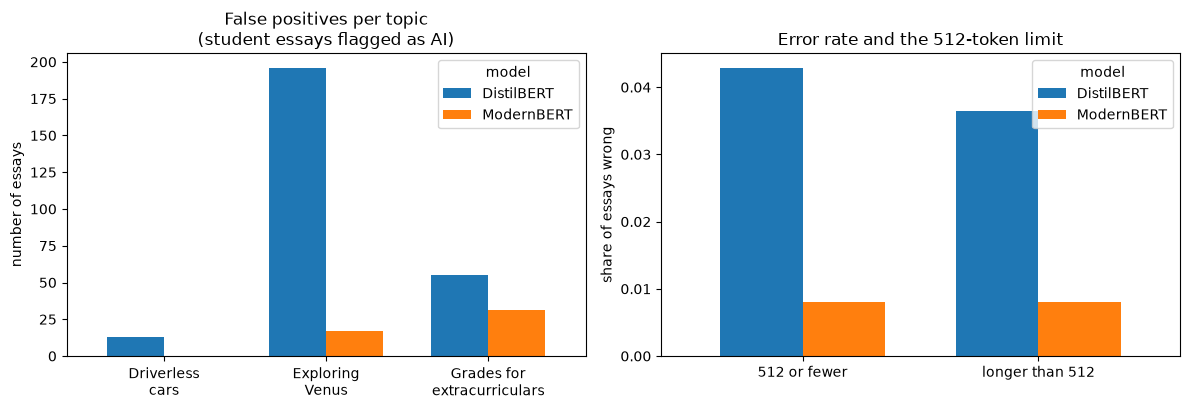

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

fp_counts[pair].rename(index=SHORT_TOPIC).plot.bar(ax=axes[0], rot=0, width=0.7)
axes[0].set_title("False positives per topic\n(student essays flagged as AI)")
axes[0].set_xlabel("")
axes[0].set_ylabel("number of essays")

head_to_head[pair].plot.bar(ax=axes[1], rot=0, width=0.7)
axes[1].set_title("Error rate and the 512-token limit")
axes[1].set_xlabel("")
axes[1].set_ylabel("share of essays wrong")

fig.tight_layout()
save_fig(fig, "distilbert_vs_modernbert")
plt.show()


## Summary

- **False positives cluster in one topic.** Exploring Venus accounts for 293 of LR's 297
  false positives, 273 of SVM's 275 and 196 of DistilBERT's 264, but only 17 of
  ModernBERT's 48. The flagged essays are formal analyses of a source article.
- **Topic words leak.** Car-related training topics lean towards student essays, and
  Driverless cars has the highest miss rate for every model.
- **Truncation is not the problem.** DistilBERT is no worse on essays it cuts at 512
  tokens. Misses rise with essay length for both transformers.
- **Only three generators are ever missed:** cohere-command, mistral7binstruct_v2 and
  llama_70b_v1.
- **ModernBERT's lower false positive rate is clear;** its bootstrap interval does not
  overlap DistilBERT's. The intervals for AI recall and ROC-AUC do overlap. The bootstrap
  resamples essays, not topics, so it understates the topic-to-topic uncertainty.